# 02 · Análisis estadístico: Airbnb en Madrid

## Introducción

El EDA dejó varias hipótesis: el precio cambia mucho con el tipo de alojamiento y con la zona, los superhosts
parecen cobrar algo más y la oferta está concentrada en cuentas con muchos anuncios. Este notebook las contrasta
formalmente. Para cada contraste se muestran **H0 y H1 antes de ejecutarlo** (definidas en `src/estadistica.py`),
el nivel de significación α, los supuestos comprobados, el **tamaño del efecto** y la conclusión.

Tres ideas guían la lectura. Primera: con miles de anuncios con precio, cualquier diferencia mínima
sale «significativa», así que lo que importa es el tamaño del efecto. Segunda: los anuncios de un mismo anfitrión
no son independientes; por eso los p-valores por anuncio se acompañan de una sensibilidad con un anuncio por
anfitrión, intervalos bootstrap por anfitrión y errores agrupados en la regresión. Tercera: todo es
observacional; los coeficientes describen asociaciones manteniendo constantes otras variables, no efectos causales.

Se usan exactamente las mismas funciones que el pipeline, con la misma semilla, y se comprueba con `assert` que
los resultados coinciden con `reports/findings.json`. Las interpretaciones tras cada resultado se generan con
cifras del propio cálculo o de `findings.json`.

In [1]:
import sys
from pathlib import Path

sys.dont_write_bytecode = True
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import config, estadistica as est, formato as fmt, visualizacion as viz

%matplotlib inline
viz.configurar_estilo()
plt.rcParams["figure.dpi"] = 72  # imágenes incrustadas ligeras
df = pd.read_parquet(config.RUTA_PARQUET)
with open(config.RUTA_FINDINGS, encoding="utf-8") as f:
    findings = json.load(f)
E = findings["estadistica"]
cp = df[df["precio_valido"]]
rng = np.random.default_rng(config.SEMILLA)


def hipotesis(clave: str) -> None:
    """Muestra H0 y H1 de un contraste antes de ejecutarlo."""
    h0, h1 = est.HIPOTESIS[clave]
    display(Markdown(f"**H0:** {h0}  \n**H1:** {h1}  \n**α = {fmt.n2(config.ALFA)}**"))


def mostrar(resultado: est.ResultadoTest, decimales_efecto: int = 3) -> None:
    """Resume un ResultadoTest."""
    efecto = resultado.tamano_efecto
    display(Markdown(
        f"- Estadístico = {fmt.n3(resultado.estadistico)}, {fmt.p_texto(resultado.p_valor)}\n"
        f"- {efecto['nombre']} = {fmt.numero(efecto['valor'], decimales_efecto)} (efecto {efecto['interpretacion']})\n"
        f"- Supuestos: {resultado.supuestos}\n"
        f"- **Conclusión:** {resultado.conclusion}"))


def lectura(texto: str) -> None:
    """Interpretación en Markdown con cifras calculadas (nunca escritas a mano)."""
    display(Markdown(texto))

## 1. Normalidad del precio y de ln(precio)

Antes de elegir contrastes conviene saber si el precio es aproximadamente normal. Se usa Shapiro-Wilk sobre una
muestra aleatoria acotada (con muestras enormes el test es demasiado sensible) y D'Agostino-K² sobre todos los
datos. La decisión no se apoya solo en el p-valor, sino también en la asimetría y en los gráficos.

In [2]:
hipotesis("normalidad")
r_precio = est.test_normalidad(cp["price"], "el precio", rng)
r_log = est.test_normalidad(cp["log_precio"], "el logaritmo del precio", rng)
mostrar(r_precio)
mostrar(r_log)
assert np.isclose(r_precio.estadistico, E["normalidad_precio"]["estadistico"])

**H0:** La variable procede de una distribución normal.  
**H1:** La variable no procede de una distribución normal.  
**α = 0,05**

- Estadístico = 49.774,065, p < 0,001
- asimetría y curtosis = 31,540 (efecto grande)
- Supuestos: {'n_total': 18785, 'n_muestra_shapiro': 5000, 'semilla_muestra': 'rng del pipeline'}
- **Conclusión:** Se rechaza H0 (p < α) con un efecto grande. El precio no es normal (asimetría 31,54, curtosis de exceso 1.469,92). Con n tan grande el test rechaza incluso desviaciones leves; la decisión de usar contrastes no paramétricos se apoya también en la asimetría y en los gráficos Q-Q.

- Estadístico = 1.014,390, p < 0,001
- asimetría y curtosis = 0,212 (efecto grande)
- Supuestos: {'n_total': 18785, 'n_muestra_shapiro': 5000, 'semilla_muestra': 'rng del pipeline'}
- **Conclusión:** Se rechaza H0 (p < α) con un efecto grande. El logaritmo del precio no es normal (asimetría 0,21, curtosis de exceso 2,01). Con n tan grande el test rechaza incluso desviaciones leves; la decisión de usar contrastes no paramétricos se apoya también en la asimetría y en los gráficos Q-Q.

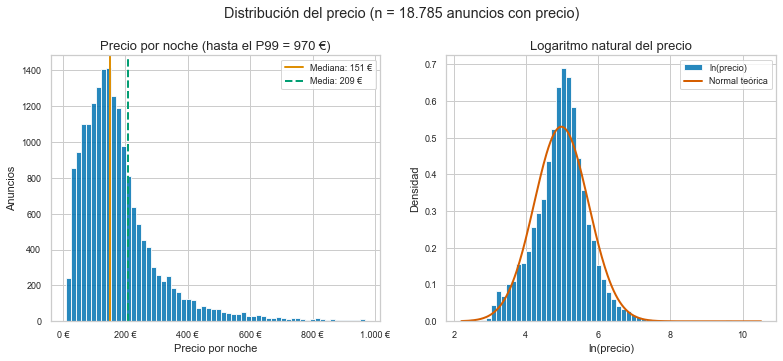

In [3]:
viz.fig_distribucion_precio(df);

In [4]:
lectura(f"**Lectura.** Se rechaza la normalidad del precio (asimetría {fmt.n2(r_precio.tamano_efecto['valor'])}) y "
        f"también la de `ln(precio)`, aunque su asimetría es solo {fmt.n2(r_log.tamano_efecto['valor'])}. Decisión: "
        "comparar grupos con contrastes de rangos (Mann-Whitney, Kruskal-Wallis) y modelar `ln(precio)` en la "
        "regresión con errores robustos.")

**Lectura.** Se rechaza la normalidad del precio (asimetría 31,54) y también la de `ln(precio)`, aunque su asimetría es solo 0,21. Decisión: comparar grupos con contrastes de rangos (Mann-Whitney, Kruskal-Wallis) y modelar `ln(precio)` en la regresión con errores robustos.

## 2. Mann-Whitney U: superhosts frente a no superhosts

Mann-Whitney compara si un grupo tiende a tener valores más altos que el otro. El tamaño de efecto es la
correlación rank-biserial: 0 indica que no hay tendencia y ±1 que un grupo supera siempre al otro.

In [5]:
hipotesis("mann_whitney_superhost")
sh = cp["host_is_superhost"]
r_mw = est.mann_whitney(cp.loc[sh, "price"], cp.loc[~sh, "price"], "superhosts", "no superhosts",
                        "mann_whitney_superhost")
mostrar(r_mw, decimales_efecto=4)
assert np.isclose(r_mw.tamano_efecto["valor"], E["mann_whitney_superhost"]["tamano_efecto"]["valor"])

**H0:** El precio de los anuncios de superhosts y de no superhosts tiene la misma distribución (P(X_superhost > X_no) = 0,5).  
**H1:** Las distribuciones difieren (contraste bilateral).  
**α = 0,05**

- Estadístico = 38.271.719,000, p < 0,001
- correlación rank-biserial = 0,0997 (efecto despreciable)
- Supuestos: {'datos_ordinales': True, 'independencia': 'parcial: un anfitrión puede tener varios anuncios (ver análisis de sensibilidad)', 'nota': 'compara dominancia estocástica, no solo medianas, si las formas difieren'}
- **Conclusión:** Se rechaza H0 (p < α): resultado estadísticamente significativo pero con efecto despreciable, sin relevancia práctica. Los anuncios de superhosts tienden a tener precios más altos (mediana de superhosts: 163,50 €; de no superhosts: 147,00 €). Es una asociación bruta, sin controlar por ubicación ni tipo.

In [6]:
umbral = E["umbrales_efecto"]["rank_biserial"][0]
lectura(f"**Lectura.** La diferencia es significativa pero el efecto es despreciable: r = "
        f"{fmt.n4(r_mw.tamano_efecto['valor'])}, justo por debajo del umbral de {fmt.n1(umbral)} que separa "
        f"despreciable de pequeño (mediana {fmt.eur2(r_mw.extra['mediana_a'])} frente a "
        f"{fmt.eur2(r_mw.extra['mediana_b'])}). Es una asociación bruta: no controla tipo ni zona.")

**Lectura.** La diferencia es significativa pero el efecto es despreciable: r = 0,0997, justo por debajo del umbral de 0,1 que separa despreciable de pequeño (mediana 163,50 € frente a 147,00 €). Es una asociación bruta: no controla tipo ni zona.

### Sensibilidad: un anuncio por anfitrión

Para comprobar que la dependencia entre anuncios del mismo anfitrión no fabrica los resultados, el pipeline
repite **todos** los contrastes principales con un anuncio elegido al azar por anfitrión.

In [7]:
s = E["sensibilidad_un_anuncio_por_host"]
pd.DataFrame({
    "decisión se mantiene": s["decisiones"],
    "p (un anuncio por host)": {k: s[k if k not in ("superhost", "tipo", "distrito") else
                                    {"superhost": "mann_whitney_superhost", "tipo": "kruskal_tipo",
                                     "distrito": "kruskal_distrito"}[k]]["p_valor"] for k in s["decisiones"]},
})

,decisión se mantiene,p (un anuncio por host)
superhost,True,1.222283e-07
tipo,True,0.000000e+00
distrito,True,1.969709e-191
chi2_tipo_superhost,True,9.877394e-24
chi2_distrito_tipo,True,7.752621e-142
chi2_multi_tipo,True,1.245942e-07


In [8]:
lectura(f"**Lectura.** Con {fmt.n0(s['n'])} anuncios (uno por anfitrión con precio), "
        + ("todas las decisiones se mantienen" if s["todas_mismas_decisiones"] else "alguna decisión cambia")
        + f"; el post-hoc de distritos conserva {s['posthoc_distrito']['n_pares_significativos']} de "
          f"{s['posthoc_distrito']['n_pares']} pares significativos, menos que con todos los anuncios, lo que "
          "confirma que los p-valores por anuncio son algo optimistas.")

**Lectura.** Con 6.546 anuncios (uno por anfitrión con precio), todas las decisiones se mantienen; el post-hoc de distritos conserva 27 de 45 pares significativos, menos que con todos los anuncios, lo que confirma que los p-valores por anuncio son algo optimistas.

## 3. Kruskal-Wallis: precio por tipo de habitación y por distrito

Kruskal-Wallis generaliza Mann-Whitney a más de dos grupos. Su tamaño de efecto, ε², se interpreta con umbrales
convencionales (pequeño, mediano, grande). Las categorías con pocos anuncios con precio (compartida y hotel) se
agrupan, y los grupos por debajo del mínimo se excluyen de la inferencia.

In [9]:
print("Umbral de agrupación:", config.MIN_N_CATEGORIA_RARA, "| mínimo por grupo:", config.MIN_N_GRUPO)

Umbral de agrupación: 200 | mínimo por grupo: 30


In [10]:
hipotesis("kruskal_tipo")
r_kt = est.kruskal(cp, "price", "tipo_habitacion_agrupado", "kruskal_tipo", "tipos de habitación")
mostrar(r_kt)

**H0:** La distribución del precio es la misma en todos los tipos de habitación.  
**H1:** Al menos un tipo de habitación tiene una distribución de precio distinta.  
**α = 0,05**

- Estadístico = 4.403,947, p < 0,001
- épsilon cuadrado = 0,234 (efecto grande)
- Supuestos: {'independencia': 'parcial (anfitriones con varios anuncios)', 'min_n_por_grupo': 30, 'n_grupos': 3}
- **Conclusión:** Se rechaza H0 (p < α) con un efecto grande. El precio difiere entre tipos de habitación: la mediana más alta es la de Alojamiento entero y la más baja la de Otras (compartida + hotel).

In [11]:
hipotesis("kruskal_distrito")
r_kd = est.kruskal(cp, "price", "neighbourhood_group_cleansed", "kruskal_distrito", "distritos")
mostrar(r_kd)
assert np.isclose(r_kd.estadistico, E["kruskal_distrito"]["estadistico"])

**H0:** La distribución del precio es la misma en todos los distritos (n ≥ 30).  
**H1:** Al menos un distrito tiene una distribución de precio distinta.  
**α = 0,05**

- Estadístico = 2.296,341, p < 0,001
- épsilon cuadrado = 0,122 (efecto mediano)
- Supuestos: {'independencia': 'parcial (anfitriones con varios anuncios)', 'min_n_por_grupo': 30, 'n_grupos': 21}
- **Conclusión:** Se rechaza H0 (p < α) con un efecto mediano. El precio difiere entre distritos: la mediana más alta es la de Salamanca y la más baja la de Moratalaz.

In [12]:
lectura(f"**Lectura.** El tipo de habitación tiene un efecto {r_kt.tamano_efecto['interpretacion']} "
        f"(ε² = {fmt.n3(r_kt.tamano_efecto['valor'])}) y el distrito un efecto "
        f"{r_kd.tamano_efecto['interpretacion']} (ε² = {fmt.n3(r_kd.tamano_efecto['valor'])}). Al ser la misma medida "
        "sobre la misma muestra, la comparación es homogénea: entre tipos hay más diferencia que entre distritos.")

**Lectura.** El tipo de habitación tiene un efecto grande (ε² = 0,234) y el distrito un efecto mediano (ε² = 0,122). Al ser la misma medida sobre la misma muestra, la comparación es homogénea: entre tipos hay más diferencia que entre distritos.

### Post-hoc de Dunn con corrección de Bonferroni

Un Kruskal-Wallis significativo dice que algún grupo difiere, no cuál. Dunn compara cada par y Bonferroni ajusta
los p-valores por el número de pares, para que la tasa de falsos positivos de la familia no se dispare.

In [13]:
hipotesis("posthoc")
ph = E["posthoc_distrito"]
print(ph["metodo"], "|", ph["n_pares_significativos"], "de", ph["n_pares"], "pares significativos")
pd.DataFrame(ph["pares"]).sort_values("p_ajustado", ascending=False).head(10).round(4)

**H0:** Para cada par de grupos, no hay diferencia en la distribución del precio.  
**H1:** El par de grupos difiere (p ajustado por Bonferroni < α).  
**α = 0,05**

Dunn con corrección de Bonferroni (scikit-posthocs) | 36 de 45 pares significativos


,grupo_a,grupo_b,p_ajustado,significativo,dif_medianas,rank_biserial
2,Arganzuela,Chamartín,1.0000,False,-4.130,-0.0664
3,Arganzuela,Chamberí,1.0000,False,-8.830,-0.0442
6,Arganzuela,Retiro,1.0000,False,1.095,-0.0092
27,Chamartín,Retiro,1.0000,False,5.225,0.0517
13,Carabanchel,Puente de Vallecas,1.0000,False,0.500,0.0177
22,Centro,Salamanca,1.0000,False,-8.340,-0.0385
24,Chamartín,Chamberí,1.0000,False,-4.700,0.0136
32,Chamberí,Retiro,1.0000,False,9.925,0.0256
38,Ciudad Lineal,Tetuán,1.0000,False,1.000,0.0038
4,Arganzuela,Ciudad Lineal,0.0019,True,18.570,0.1341


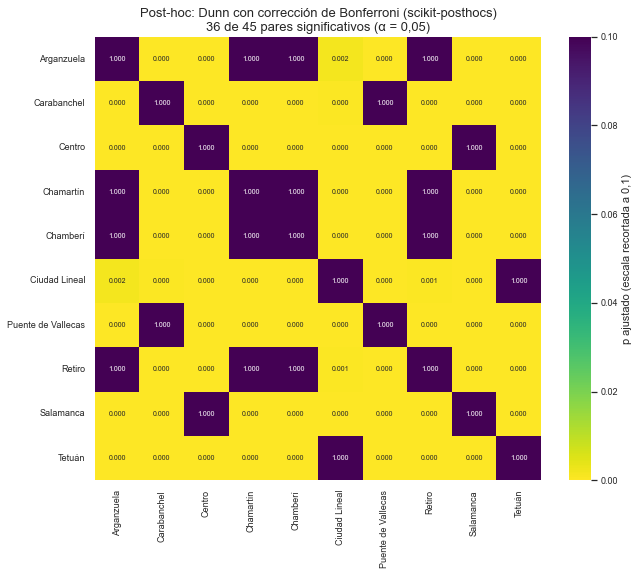

In [14]:
viz.fig_posthoc_distritos(findings);

In [15]:
emp = E["top_distritos_empate"]
lectura(f"**Lectura.** {ph['n_pares_significativos']} de {ph['n_pares']} pares de distritos difieren. Los dos distritos "
        f"de mediana más alta, {emp['a']} y {emp['b']}, tienen p ajustado = {fmt.n3(emp['p_ajustado'])}: "
        + ("están **empatados estadísticamente**." if emp["empate"] else "sí se distinguen."))

**Lectura.** 36 de 45 pares de distritos difieren. Los dos distritos de mediana más alta, Salamanca y Centro, tienen p ajustado = 1,000: están **empatados estadísticamente**.

## 4. Chi-cuadrado con V de Cramér

El chi-cuadrado de independencia contrasta si dos variables categóricas están asociadas; la V de Cramér mide la
fuerza de la asociación. Se comprueba que las frecuencias esperadas no sean demasiado bajas.

In [16]:
for clave, fila, col, etiqueta in [
    ("chi2_tipo_superhost", "tipo_habitacion_agrupado", "host_is_superhost", "tipo de habitación y ser superhost"),
    ("chi2_multi_tipo", "es_multianuncio", "tipo_habitacion_agrupado", "ser multi-anuncio y tipo de habitación"),
]:
    hipotesis(clave)
    mostrar(est.chi_cuadrado(df, fila, col, clave, etiqueta))

**H0:** El tipo de habitación y ser superhost son independientes.  
**H1:** Existe asociación entre tipo de habitación y ser superhost.  
**α = 0,05**

- Estadístico = 181,136, p < 0,001
- V de Cramér = 0,089 (efecto despreciable)
- Supuestos: {'min_esperada': 45.72140724393093, 'pct_celdas_esperada_menor_5': 0.0, 'cumple_esperadas': True, 'correccion_yates': False}
- **Conclusión:** Se rechaza H0 (p < α): resultado estadísticamente significativo pero con efecto despreciable, sin relevancia práctica. Hay asociación entre tipo de habitación y ser superhost (V de Cramér = 0,089).

**H0:** Ser anfitrión multi-anuncio y el tipo de habitación son independientes.  
**H1:** Existe asociación entre ser multi-anuncio y el tipo de habitación.  
**α = 0,05**

- Estadístico = 178,117, p < 0,001
- V de Cramér = 0,088 (efecto despreciable)
- Supuestos: {'min_esperada': 50.83941321563027, 'pct_celdas_esperada_menor_5': 0.0, 'cumple_esperadas': True, 'correccion_yates': False}
- **Conclusión:** Se rechaza H0 (p < α): resultado estadísticamente significativo pero con efecto despreciable, sin relevancia práctica. Hay asociación entre ser multi-anuncio y tipo de habitación (V de Cramér = 0,088).

In [17]:
hipotesis("chi2_distrito_tipo")
r = E["chi2_distrito_tipo"]
print("V de Cramér =", fmt.n3(r["tamano_efecto"]["valor"]), "|", fmt.p_texto(r["p_valor"]),
      "| % celdas con esperada < 5:", fmt.pct1(r["supuestos"]["pct_celdas_esperada_menor_5"]))
print("Conclusión:", r["conclusion"])

**H0:** El distrito y el tipo de habitación son independientes.  
**H1:** Existe asociación entre distrito y tipo de habitación.  
**α = 0,05**

V de Cramér = 0,169 | p < 0,001 | % celdas con esperada < 5: 13,0 %
Conclusión: Se rechaza H0 (p < α) con un efecto pequeño. Hay asociación entre distrito y tipo de habitación (V de Cramér = 0,169).


In [18]:
lectura(f"**Lectura.** Las tres asociaciones son significativas, pero solo la de distrito y tipo de habitación "
        f"tiene un efecto no despreciable (V = {fmt.n3(r['tamano_efecto']['valor'])}): la mezcla de alojamientos "
        f"cambia de una zona a otra. Tipo × superhost (V = {fmt.n3(E['chi2_tipo_superhost']['tamano_efecto']['valor'])}) "
        "es estadísticamente significativa sin relevancia práctica.")

**Lectura.** Las tres asociaciones son significativas, pero solo la de distrito y tipo de habitación tiene un efecto no despreciable (V = 0,169): la mezcla de alojamientos cambia de una zona a otra. Tipo × superhost (V = 0,089) es estadísticamente significativa sin relevancia práctica.

## 5. Intervalos de confianza bootstrap de la mediana

El bootstrap remuestrea los datos muchas veces para ver cuánto varía la mediana. Se hace de dos formas:
remuestreando anuncios (supone independencia) y remuestreando **anfitriones** con todos sus anuncios, que respeta
la dependencia y da intervalos más anchos y realistas.

In [19]:
b = E["bootstrap"]
tabla_ic = pd.concat([pd.DataFrame(b["tipo"]), pd.DataFrame(b["distritos"])])
tabla_ic[["grupo", "n", "n_anfitriones", "mediana", "ic_inf", "ic_sup", "ic_inf_cluster", "ic_sup_cluster"]].round(2)

,grupo,n,n_anfitriones,mediana,ic_inf,ic_sup,ic_inf_cluster,ic_sup_cluster
0,Alojamiento entero,13561,4561,173.63,172.00,175.36,167.00,180.00
1,Habitación privada,5059,2228,74.00,71.32,75.60,66.00,81.67
2,Otras (compartida + hotel),165,46,29.00,27.00,35.00,24.00,64.00
0,Salamanca,1314,528,188.34,180.23,194.25,176.00,202.00
1,Centro,7866,2760,180.00,177.50,182.20,173.00,187.70
2,Chamberí,1159,441,155.40,149.23,162.00,136.50,170.20
3,Chamartín,699,266,150.70,144.76,157.50,139.00,164.80
4,Arganzuela,918,480,146.57,138.62,151.25,132.80,155.45
5,Retiro,656,294,145.48,137.76,156.01,126.00,163.39
6,Ciudad Lineal,631,349,128.00,120.50,133.50,114.98,137.33


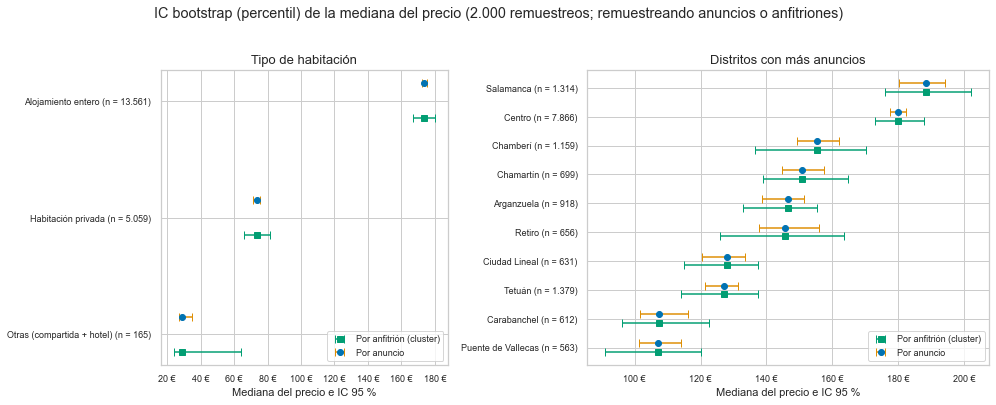

In [20]:
viz.fig_ic_bootstrap(findings);

In [21]:
t0, t1 = b["tipo"][0], b["tipo"][1]
lectura(f"**Lectura.** El IC por anfitrión de {t0['grupo'].lower()} ({fmt.eur0(t0['ic_inf_cluster'])}–"
        f"{fmt.eur0(t0['ic_sup_cluster'])}) es más ancho que el IC por anuncio ({fmt.eur0(t0['ic_inf'])}–"
        f"{fmt.eur0(t0['ic_sup'])}), como debe ser con observaciones dependientes, y aun así no se solapa con el de "
        f"{t1['grupo'].lower()} ({fmt.eur0(t1['ic_inf_cluster'])}–{fmt.eur0(t1['ic_sup_cluster'])}).")

**Lectura.** El IC por anfitrión de alojamiento entero (167 €–180 €) es más ancho que el IC por anuncio (172 €–175 €), como debe ser con observaciones dependientes, y aun así no se solapa con el de habitación privada (66 €–82 €).

## 6. Regresión OLS sobre ln(precio)

La regresión permite comparar a igualdad de otras variables. Se modela `ln(precio)`, así que cada coeficiente β se
interpreta como un cambio porcentual `100·(e^β − 1)`. Controles: tipo, capacidad, dormitorios, baños, amenities,
distancia, superhost, multi-anuncio, estancia larga, licencia, distrito y **mes de la cotización**. Los errores
se agrupan por anfitrión (con HC3 como comparación) y el contraste global usa esa misma covarianza.

In [22]:
hipotesis("ols")
ols = est.ajustar_ols(df, config.CIUDADES[config.CIUDAD_POR_DEFECTO].distrito_referencia)
artefactos = {"residuos": ols.pop("_residuos"), "ajustados": ols.pop("_ajustados")}
ols.pop("_indices")
print("n efectivo:", fmt.n0(ols["n_efectivo"]), "| R² ajustado:", fmt.n3(ols["r2_ajustado"]),
      "| F (cluster):", fmt.n1(ols["f_cluster"]), "| F no robusto:", fmt.n1(ols["f_no_robusto"]))
print("Diagnóstico:", {k: round(v, 4) if isinstance(v, float) else v for k, v in ols["diagnostico"].items()})
assert np.isclose(ols["r2_ajustado"], E["ols"]["r2_ajustado"])
coef = pd.DataFrame(ols["coeficientes"])
coef.loc[~coef["es_distrito"] & ~coef["es_mes"], ["nombre", "pct", "ic_inf_pct", "ic_sup_pct", "p_cluster", "p_holm"]].round(4)

**H0:** Cada coeficiente β es 0 (la variable no se asocia con ln(precio) controlando por el resto).  
**H1:** β ≠ 0.  
**α = 0,05**

n efectivo: 18.159 | R² ajustado: 0,601 | F (cluster): 189,1 | F no robusto: 595,4
Diagnóstico: {'breusch_pagan_lm': 1707.6245, 'breusch_pagan_p': 0.0, 'heterocedasticidad': True, 'jarque_bera': 3455.923, 'jarque_bera_p': 0.0, 'asimetria_residuos': 0.5595, 'curtosis_residuos': 4.8209, 'n_cook_mayor_4_n': 999, 'pct_cook_mayor_4_n': 5.5014}


,nombre,pct,ic_inf_pct,ic_sup_pct,p_cluster,p_holm
0,Tipo: Habitación privada,-24.1667,-28.7355,-19.3050,0.0000,0.0000
1,Tipo: Otras (compartida + hotel),-46.2444,-58.9634,-29.5833,0.0000,0.0002
2,Licencia: Con nº de registro,0.6884,-3.1775,4.7086,0.7313,1.0000
3,Licencia: Exenta,-0.2980,-4.1934,3.7557,0.8833,1.0000
4,Licencia: Otro / en proceso,11.9183,-0.3080,25.6441,0.0564,1.0000
31,Capacidad (+1 persona),10.9559,9.4004,12.5336,0.0000,0.0000
32,Dormitorios (+1),5.4294,2.0704,8.8990,0.0014,0.0316
33,Baños (+1),0.3073,-3.6344,4.4101,0.8808,1.0000
34,Baño compartido,-26.4291,-31.6554,-20.8031,0.0000,0.0000
35,Amenities (+1),0.3312,0.1899,0.4727,0.0000,0.0001


In [23]:
lectura(f"**Lectura.** El modelo explica un {fmt.pct1(ols['r2_ajustado'] * 100)} de la varianza de `ln(precio)` "
        f"dentro de muestra. De los {ols['n_coeficientes']} coeficientes, {ols['n_significativos']} son significativos "
        f"con α y {ols['n_significativos_holm']} tras la corrección de Holm por multiplicidad. El superhost se asocia "
        f"con {fmt.signo_pct(E['ols']['coef_superhost']['pct'])} (IC {fmt.signo_pct(E['ols']['coef_superhost']['ic_inf_pct'])}"
        f" a {fmt.signo_pct(E['ols']['coef_superhost']['ic_sup_pct'])}, p Holm = {fmt.n3(E['ols']['coef_superhost']['p_holm'])}): "
        "evidencia débil de una prima pequeña, no robusta.")

**Lectura.** El modelo explica un 60,1 % de la varianza de `ln(precio)` dentro de muestra. De los 46 coeficientes, 27 son significativos con α y 24 tras la corrección de Holm por multiplicidad. El superhost se asocia con +3,4 % (IC +0,5 % a +6,5 %, p Holm = 0,497): evidencia débil de una prima pequeña, no robusta.

### Multicolinealidad: VIF y GVIF

Sin dummies de distrito el VIF es bajo, pero la distancia al centro y el distrito están muy relacionados. Con la
matriz completa, el GVIF por término mide esa colinealidad; por eso el coeficiente de distancia se lee como un
efecto **dentro** de cada distrito.

In [24]:
pd.DataFrame(ols["gvif"])[["nombre", "gl", "gvif", "gvif_ajustado"]].head(6).round(2)

,nombre,gl,gvif,gvif_ajustado
0,Distancia al centro (+1 km),1,8.98,3.00
1,Capacidad (+1 persona),1,2.26,1.50
2,Baño compartido,1,1.84,1.36
3,Dormitorios (+1),1,1.82,1.35
4,Amenities (+1),1,1.78,1.33
5,ln(1 + nº reseñas),1,1.59,1.26


In [25]:
td, ref = E["ols"]["top_distritos"][0], E["ols"]["referencia_distrito"]
lectura(f"**Lectura.** El VIF de la distancia con dummies es {fmt.n2(ols['vif_completo_distancia'])} (sin ellas, el máximo "
        f"es {fmt.n2(ols['vif_max']['vif'])}). Esto explica un resultado que parece paradójico: "
        f"{td['nombre'].replace('Distrito: ', '')} tiene un coeficiente de {fmt.signo_pct(td['pct'])} frente a "
        f"{E['ols']['referencias']['distrito']}, pero su mediana bruta es {fmt.eur2(td['mediana_bruta'])} frente a "
        f"{fmt.eur2(ref['mediana_bruta'])}. Está a {fmt.n1(td['distancia_media_km'])} km de media y el término de "
        f"distancia ya implica un cambio de {fmt.signo_pct(td['efecto_distancia_pct'])} a esa distancia: la dummy compensa esa penalización.")

**Lectura.** El VIF de la distancia con dummies es 8,98 (sin ellas, el máximo es 2,20). Esto explica un resultado que parece paradójico: Barajas tiene un coeficiente de +48,6 % frente a Centro, pero su mediana bruta es 122,00 € frente a 178,34 €. Está a 11,6 km de media y el término de distancia ya implica un cambio de -44,8 % a esa distancia: la dummy compensa esa penalización.

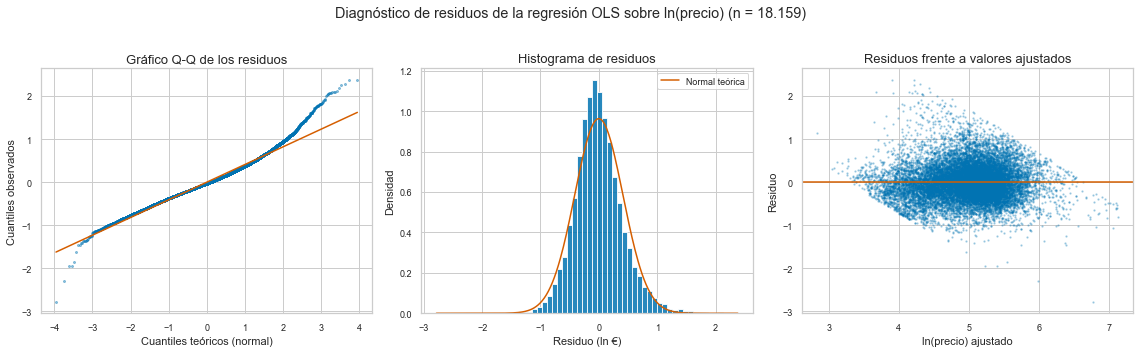

In [26]:
viz.fig_ols_residuos(artefactos);

In [27]:
lectura(f"**Lectura.** Los residuos no son normales (colas pesadas) y hay heterocedasticidad (Breusch-Pagan "
        f"{fmt.p_texto(ols['diagnostico']['breusch_pagan_p'])}), de ahí los errores robustos. El borde diagonal del "
        "gráfico de residuos frente a ajustados refleja el truncamiento por excluir outliers de la variable dependiente.")

**Lectura.** Los residuos no son normales (colas pesadas) y hay heterocedasticidad (Breusch-Pagan p < 0,001), de ahí los errores robustos. El borde diagonal del gráfico de residuos frente a ajustados refleja el truncamiento por excluir outliers de la variable dependiente.

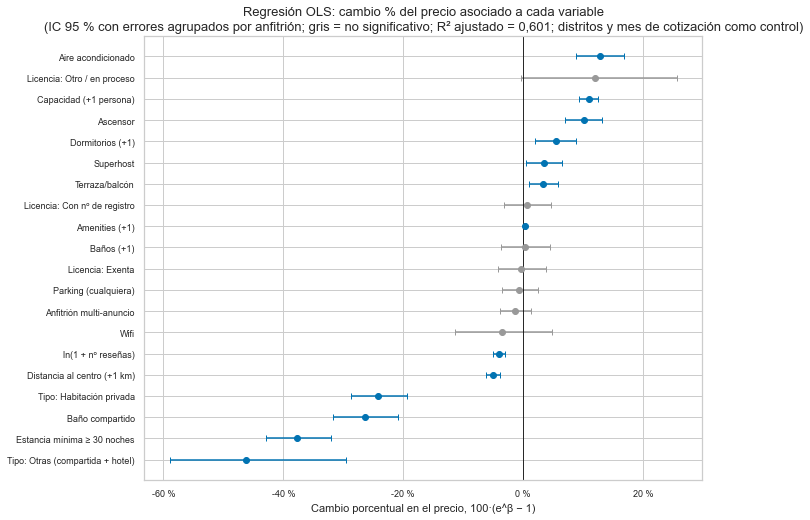

In [28]:
viz.fig_ols_coeficientes(findings);

### Sensibilidades del OLS

Un coeficiente es más creíble si no depende de decisiones concretas de análisis. Se comparan cuatro
especificaciones alternativas: sin control de mes, con outliers, sin observaciones influyentes (distancia de Cook
alta) y sin estancias mensuales.

In [29]:
o = E["ols"]
filas = []
for t, c in o["sensibilidad_sin_mes"]["coeficientes"].items():
    filas.append({"variable": c["nombre"], "principal": c["pct_principal"], "sin mes": c["pct_alternativo"],
                  "sin influyentes": o["sensibilidad_sin_influyentes"]["coeficientes"].get(t, {}).get("pct"),
                  "sin mensuales": o["sensibilidad_sin_mensuales"]["coeficientes"].get(t, {}).get("pct_alternativo")})
pd.DataFrame(filas).set_index("variable").round(2)

,principal,sin mes,sin influyentes,sin mensuales
variable,,,,
Capacidad (+1 persona),10.96,11.98,9.46,10.12
Baño compartido,-26.43,-26.45,-31.99,-29.14
Distancia al centro (+1 km),-4.98,-4.74,-5.59,-5.20
Superhost,3.44,2.53,3.53,3.47
Estancia mínima ≥ 30 noches,-37.66,-45.03,-37.16,NaN
Aire acondicionado,12.77,15.03,13.40,10.54


In [30]:
lectura(f"**Lectura.** Los signos se mantienen en todas las especificaciones (con outliers, "
        f"{o['sensibilidad_con_outliers']['n_signos_coinciden']} de {o['sensibilidad_con_outliers']['n_significativos']} "
        "coeficientes significativos conservan el signo). El coeficiente que más cambia es el de la estancia mínima "
        "larga al quitar el control de mes, porque las cotizaciones lejanas son sobre todo estancias mensuales.")

**Lectura.** Los signos se mantienen en todas las especificaciones (con outliers, 27 de 27 coeficientes significativos conservan el signo). El coeficiente que más cambia es el de la estancia mínima larga al quitar el control de mes, porque las cotizaciones lejanas son sobre todo estancias mensuales.

## 7. Modelo predictivo (complementario)

Un HistGradientBoosting con una lista blanca de variables (sin ninguna derivada del precio) mide cuánto se puede
predecir el precio. La validación agrupa por anfitrión: ningún anfitrión está a la vez en entrenamiento y prueba,
y la imputación y la agrupación de categorías raras se aprenden dentro del Pipeline solo con el entrenamiento. Por
coste, este notebook lee el resultado de `findings.json` en lugar de reentrenar.

,R² medio
"HGB, GroupKFold (todas las filas con precio)",0.669
Línea base (mediana),-0.007
"HGB, partición aleatoria (optimista)",0.755
"Lineal, variables del OLS (mismas filas y particiones)",0.581
"HGB, variables del OLS (mismas filas y particiones)",0.637
"HGB, todas las variables (mismas filas y particiones)",0.697


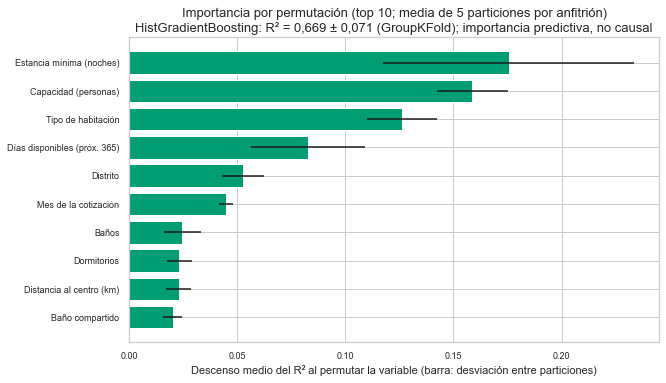

In [31]:
ml = E["ml"]
if ml["ejecutado"]:
    cv, cm = ml["cv"], ml["comparacion_misma_muestra"]
    display(pd.DataFrame({
        "R² medio": {"HGB, GroupKFold (todas las filas con precio)": cv["r2_media"],
                     "Línea base (mediana)": ml["cv_base"]["r2_media"],
                     "HGB, partición aleatoria (optimista)": ml["aleatorio"]["r2"],
                     "Lineal, variables del OLS (mismas filas y particiones)": cm["lineal_vars_ols"]["r2_media"],
                     "HGB, variables del OLS (mismas filas y particiones)": cm["hgb_vars_ols"]["r2_media"],
                     "HGB, todas las variables (mismas filas y particiones)": cm["hgb_todas"]["r2_media"]},
    }).round(3))
    viz.fig_importancia_variables(findings)
else:
    print("Modelo no ejecutado:", ml["motivo"])

In [32]:
if ml["ejecutado"]:
    lectura(f"**Lectura.** Para anfitriones no vistos, R² = {fmt.n3(cv['r2_media'])} ± {fmt.n3(cv['r2_std'])} y mediana "
            f"del error absoluto ≈ {fmt.eur0(cv['medae_eur_media'])} por noche. Con partición aleatoria saldría "
            f"{fmt.n3(ml['aleatorio']['r2'])}, porque el {fmt.pct1(ml['aleatorio']['pct_test_con_anfitrion_en_train'])} "
            "de los anuncios de prueba comparte anfitrión con el entrenamiento. En la comparación homogénea, el no "
            "lineal supera al lineal con las mismas variables; la importancia por permutación es predictiva, no causal.")

**Lectura.** Para anfitriones no vistos, R² = 0,669 ± 0,071 y mediana del error absoluto ≈ 30 € por noche. Con partición aleatoria saldría 0,755, porque el 74,5 % de los anuncios de prueba comparte anfitrión con el entrenamiento. En la comparación homogénea, el no lineal supera al lineal con las mismas variables; la importancia por permutación es predictiva, no causal.

## Conclusión

Las diferencias de precio por tipo de habitación y por distrito son significativas y relevantes, y resisten la
sensibilidad con un anuncio por anfitrión; el tipo de habitación muestra la mayor diferencia entre grupos con la
misma medida de efecto. La diferencia bruta por superhost es significativa pero despreciable, y al controlar en
la regresión la evidencia de una prima es débil y no robusta: si existe, es pequeña. Los coeficientes de distrito
hay que leerlos condicionados a la distancia, que dentro de un distrito se asocia con precios más bajos. Los
resultados son estables frente a outliers, observaciones influyentes, el control de mes y la exclusión de
estancias mensuales. El modelo predictivo, validado sin repetir anfitriones, mejora claramente a la línea base,
pero su capacidad de generalizar es menor que la que sugeriría una partición aleatoria.

Todo ello son asociaciones en datos observacionales de un único snapshot. La interpretación completa, las
limitaciones y las recomendaciones (formuladas como hipótesis) están en `reports/informe.md`.